In [2]:
# Sabse pehle Drive mount karein
from google.colab import drive
drive.mount('/content/drive')

# Phir Google Drive ke andar project folder banayein aur navigate karein
!mkdir -p "/content/drive/MyDrive/WindGuard_Data"
%cd "/content/drive/MyDrive/WindGuard_Data"

# Ab yahan download (Step 1) aur extract (Step 2) karein

Mounted at /content/drive
/content/drive/MyDrive/WindGuard_Data


In [5]:
import os
import requests
from tqdm.notebook import tqdm

# 1. Google Drive ka directory path
output_dir = "/content/drive/MyDrive/WindGuard_Project"
os.makedirs(output_dir, exist_ok=True)

# 2. Zenodo metadata fetch karein
record_id = "16807551"
url = f"https://zenodo.org/api/records/{record_id}"

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'
}

response = requests.get(url, headers=headers, timeout=60)
response.raise_for_status()
files = response.json().get("files", [])

file_lookup = {f["key"]: f for f in files}

# 3. Kaun-kaun si files download karni hain:
# Status/Event file ka jo bhi naam list mein ho (jaise Kelmarsh_Status_...csv) use yahan add kar sakte hain
selected_files = [
    "Kelmarsh_SCADA_2019_3085.zip",
    "Kelmarsh_WT_static.csv",
    "Kelmarsh_WT_dataSignalMapping.csv"
]

# 4. Stream download with progress bar
for filename in selected_files:
    if filename not in file_lookup:
        print(f"File nahi mili Zenodo par: {filename}")
        continue

    item = file_lookup[filename]
    path = os.path.join(output_dir, filename)

    if os.path.exists(path) and os.path.getsize(path) == item["size"]:
        print("Already downloaded:", filename)
        continue

    # Zenodo API v4 mein direct download link
    download_url = item["links"].get("content", item["links"]["self"])

    print(f"\nDownloading: {filename} ({item['size'] / 1024**2:.2f} MB)")
    with requests.get(download_url, headers=headers, stream=True, timeout=(30, 300)) as r:
        r.raise_for_status()
        total_size = int(r.headers.get("content-length", item["size"]))

        with open(path, "wb") as out, tqdm(
            desc=filename,
            total=total_size,
            unit="B",
            unit_scale=True,
            unit_divisor=1024
        ) as pbar:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    out.write(chunk)
                    pbar.update(len(chunk))

    print("Download finished:", filename)

Already downloaded: Kelmarsh_SCADA_2019_3085.zip
Already downloaded: Kelmarsh_WT_static.csv
Already downloaded: Kelmarsh_WT_dataSignalMapping.csv


Is code mein kya ho raha hai aur output mein kya aayega:
glob.glob(...): Yeh check karega ki zip file se total kitni CSV files extract hui hain (har turbine ki alag file aayi hai ya month-wise).

pd.read_csv(..., nrows=5): Poora 1 saal ka data ek saath memory mein load karne se pehle hum sirf 5 rows load kar rahe hain. Isse Colab ki RAM par koi load nahi padega aur seconds mein run ho jayega.

Output mein aapko Total files, file ka asli naam, aur Kelmarsh ke first 10 sensors ke exact column names milenge. Isse hume pata chal jayega ki timestamp, power aur wind speed ka column kis exact naam se likha gaya hai.

In [6]:
import os

# Dekhte hain folder mein abhi kaunsi files/zips present hain
current_folder = "/content/drive/MyDrive/WindGuard_Project"

if os.path.exists(current_folder):
    print("Folder ke andar ye items hain:\n")
    for item in os.listdir(current_folder):
        item_path = os.path.join(current_folder, item)
        size_mb = os.path.getsize(item_path) / (1024 * 1024)
        print(f" - {item} ({size_mb:.2f} MB)")
else:
    print("Folder exist nahi karta! Drive mount check karein.")

Folder ke andar ye items hain:

 - Kelmarsh_SCADA_2019_3085.zip (296.85 MB)
 - Kelmarsh_WT_static.csv (0.00 MB)
 - Kelmarsh_WT_dataSignalMapping.csv (0.00 MB)


Is code se kya pata chalega:Kya Kelmarsh_SCADA_2019_3085.zip file download hokar Drive mein save hui hai ya nahi?   Agar zip file wahan maujood hai, toh uska exact size kitna hai?Agar file kisi aur naam ya subfolder mein hai, toh uska exact path saamne aa jayega.

In [8]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/WindGuard_Project/Kelmarsh_SCADA_2019_3085.zip"
extract_dir = "/content/drive/MyDrive/WindGuard_Project/extracted_scada_2019"

# Directory create karein
os.makedirs(extract_dir, exist_ok=True)

print("ZIP file extract ho rahi hai, 15-30 seconds wait karein...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("\nExtraction complete! Files extract ho chuki hain.")

ZIP file extract ho rahi hai, 15-30 seconds wait karein...

Extraction complete! Files extract ho chuki hain.


Is code mein kya ho raha hai:
zipfile.ZipFile(zip_path, 'r'): Yeh Python ke built-in zip handler se file ko read karega.

extractall(extract_dir): Zip ke andar jitni bhi turbines ki CSV files hain, unhe extracted_scada_2019 naam ke folder mein safely unpack kar dega.

In [9]:
import glob
import os

extract_dir = "/content/drive/MyDrive/WindGuard_Project/extracted_scada_2019"

# Saari files locate karein jo extract hui hain
all_files = sorted(glob.glob(f"{extract_dir}/**/*", recursive=True))
csv_files = [f for f in all_files if f.endswith('.csv')]

print(f"Total CSV files extracted: {len(csv_files)}\n")
print("Files ki details:")
for i, f in enumerate(csv_files, 1):
    size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f"{i}. {os.path.basename(f)} ({size_mb:.2f} MB)")

Total CSV files extracted: 12

Files ki details:
1. Status_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv (0.70 MB)
2. Status_Kelmarsh_2_2019-01-01_-_2020-01-01_229.csv (0.69 MB)
3. Status_Kelmarsh_3_2019-01-01_-_2020-01-01_230.csv (1.05 MB)
4. Status_Kelmarsh_4_2019-01-01_-_2020-01-01_231.csv (0.78 MB)
5. Status_Kelmarsh_5_2019-01-01_-_2020-01-01_232.csv (0.80 MB)
6. Status_Kelmarsh_6_2019-01-01_-_2020-01-01_233.csv (1.21 MB)
7. Turbine_Data_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv (140.44 MB)
8. Turbine_Data_Kelmarsh_2_2019-01-01_-_2020-01-01_229.csv (143.49 MB)
9. Turbine_Data_Kelmarsh_3_2019-01-01_-_2020-01-01_230.csv (143.28 MB)
10. Turbine_Data_Kelmarsh_4_2019-01-01_-_2020-01-01_231.csv (143.17 MB)
11. Turbine_Data_Kelmarsh_5_2019-01-01_-_2020-01-01_232.csv (143.58 MB)
12. Turbine_Data_Kelmarsh_6_2019-01-01_-_2020-01-01_233.csv (143.58 MB)


Is code mein kya ho raha hai:
glob.glob(...): Extracted folder ke subfolders mein jaakar har file ka path scan karta hai.

csv_files: Sirf data CSVs ko filter karke unka exact count nikalta hai.

Output mein har file ka naam aur size (MB mein) show hoga, jisse clear ho jayega ki saari 6 turbines ki files sahi tarike se aa chuki hain ya nahi.

In [10]:
import pandas as pd
import os

extract_dir = "/content/drive/MyDrive/WindGuard_Project/extracted_scada_2019"

# Turbine 1 ki Status/Event file load karein
status_file = os.path.join(extract_dir, "Status_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv")

df_status = pd.read_csv(status_file, nrows=5)

print("Status Log Shape (Sample):", df_status.shape)
print("\nColumns in Status Log:")
for col in df_status.columns:
    print(" -", col)

print("\nSample Data:")
display(df_status)

Status Log Shape (Sample): (5, 1)

Columns in Status Log:
 - # This file was exported by Greenbyte at 2022-01-27 16:47:37. Please see https://www.greenbyte.com for more information about Greenbyte.

Sample Data:


,# This file was exported by Greenbyte at 2022-01-27 16:47:37. Please see https://www.greenbyte.com for more information about Greenbyte.
0,#
1,# Turbine: Kelmarsh 1
2,# Turbine type: Senvion MM92 (Senvion MM92 kW)
3,# Time zone: UTC
4,# Time interval: 2019-01-01 00:00:00 - 2020-01...


Status file mein timestamp kis column mein likha hai (e.g., Timestamp, Start time, End time).   Error ya event ko describe karne wale columns ke exact naam kya hain (e.g., Status, Message, IEC Category, Fault code).

Output mein clearly dikh raha hai ki file ke upar metadata lines hain jo # se start hoti hain (# Turbine: Kelmarsh 1, # Turbine type: Senvion MM92, etc.).   Is wajah se Pandas ne # This file was exported... wali pehli line ko hi column header samajh liya.   Humein Pandas ko batana hoga ki metadata header rows ko skip kare ya comments ignore kare.

In [11]:
import pandas as pd
import os

extract_dir = "/content/drive/MyDrive/WindGuard_Project/extracted_scada_2019"
status_file = os.path.join(extract_dir, "Status_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv")

# Comment lines (#) ko ignore karke clean data load karein
# Kelmarsh Greenbyte exports mein usually 9 ya 10 lines comment hoti hain
df_status = pd.read_csv(status_file, comment='#', skipinitialspace=True)

print("Status Log Shape:", df_status.shape)
print("\nActual Columns in Status Log:")
for col in df_status.columns:
    print(" -", col)

print("\nFirst 5 status records:")
display(df_status.head())

Status Log Shape: (7821, 9)

Actual Columns in Status Log:
 - Timestamp start
 - Timestamp end
 - Duration
 - Status
 - Code
 - Message
 - Comment
 - Service contract category
 - IEC category

First 5 status records:


,Timestamp start,Timestamp end,Duration,Status,Code,Message,Comment,Service contract category,IEC category
0,2019-01-01 11:03:12,2019-01-01 11:05:30,00:02:18,Stop,710,Battery test,NaN,Operating states (28),Technical Standby
1,2019-01-01 11:03:12,-,-,Informational,100030,Brake program 180,NaN,NaN,Technical Standby
2,2019-01-01 11:05:30,-,-,Informational,0,System OK,NaN,System OK (32),Full Performance
3,2019-01-01 11:05:30,-,-,Informational,100110,Bypass limit switches,NaN,NaN,Full Performance
4,2019-01-01 11:05:36,-,-,Informational,100130,Automatic start-up,NaN,NaN,Full Performance


In [12]:
# 1. Dekhein kis-kis type ke Status exist karte hain
print("--- Unique Status Categories ---")
print(df_status['Status'].value_counts())

# 2. 'Stop' wale events filter karein aur top messages dekhein
stops_df = df_status[df_status['Status'].str.lower() == 'stop']
print(f"\nTotal 'Stop' events count: {len(stops_df)}")

print("\n--- Top 15 Reasons for Turbine Stop ---")
print(stops_df['Message'].value_counts().head(15))

--- Unique Status Categories ---
Status
Informational    7606
Stop              118
Warning            87
Communication      10
Name: count, dtype: int64

Total 'Stop' events count: 118

--- Top 15 Reasons for Turbine Stop ---
Message
Battery test                        50
Cable autounwind                    19
Hydraulic oil flushing operation     9
Manual stop - on site                7
Timeout ready for connection         4
Grid loss                            4
Manual stop - remote                 4
Frequency converter not ready        4
Tower oscillation Y level 1          3
Manual stop without login            2
Low hydraulic pressure               2
Manual brake                         2
Tower oscillation X level 2          2
Icing (stop)                         1
Deviation winddirection > 60°        1
Name: count, dtype: int64


Status mein kitne normal informational logs hain aur kitne actual stops/faults hain.   Message ke counts se saaf pata chal jayega ki stops routine maintenance/tests ki wajah se huye hain ya kisi component (gearbox, generator, pitch, temperature) ke alarm ki wajah se.

Is code se kya clear hoga:SCADA file mein total kitne columns (sensors) hain.   Timestamp, Wind Speed, Active Power aur Temperature sensors ke exact variable names mil jayenge, jisse hum un par plots aur analysis start kar sakein.

In [13]:
import pandas as pd
import os

extract_dir = "/content/drive/MyDrive/WindGuard_Project/extracted_scada_2019"
scada_file = os.path.join(extract_dir, "Turbine_Data_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv")

# Line 0 se 8 tak metadata skip karein, Line 9 header banegi
df_sample = pd.read_csv(scada_file, skiprows=9, nrows=5)

# Line 9 ke shuruat mein jo '# ' tha usse pehle column name se clean karein
df_sample.columns = [col.replace('# ', '').strip() for col in df_sample.columns]

print(f"SCADA Columns Count: {len(df_sample.columns)}")
print(f"Sample Rows Loaded: {len(df_sample)}")

print("\n--- Key Verified Sensor Columns ---")
key_patterns = ['date', 'wind speed', 'power', 'bearing', 'gear oil', 'rotor', 'blade angle']
matched_cols = [c for c in df_sample.columns if any(p in c.lower() for p in key_patterns)]

for i, col in enumerate(matched_cols[:25], 1):
    print(f"{i}. {col}")

SCADA Columns Count: 299
Sample Rows Loaded: 5

--- Key Verified Sensor Columns ---
1. Date and time
2. Wind speed (m/s)
3. Wind speed, Standard deviation (m/s)
4. Wind speed, Minimum (m/s)
5. Wind speed, Maximum (m/s)
6. Wind speed Sensor 1 (m/s)
7. Wind speed Sensor 1, Standard deviation (m/s)
8. Wind speed Sensor 1, Minimum (m/s)
9. Wind speed Sensor 1, Maximum (m/s)
10. Wind speed Sensor 2 (m/s)
11. Wind speed Sensor 2, Standard deviation (m/s)
12. Wind speed Sensor 2, Minimum (m/s)
13. Wind speed Sensor 2, Maximum (m/s)
14. Density adjusted wind speed (m/s)
15. Power (kW)
16. Potential power default PC (kW)
17. Power, Standard deviation (kW)
18. Power, Minimum (kW)
19. Power, Maximum (kW)
20. Potential power learned PC (kW)
21. Potential power reference turbines (kW)
22. Cascading potential power (kW)
23. Cascading potential power for performance (kW)
24. Potential power met mast anemometer (kW)
25. Potential power primary reference turbines (kW)


In [14]:
import pandas as pd
import numpy as np
import os

extract_dir = "/content/drive/MyDrive/WindGuard_Project/extracted_scada_2019"
scada_file = os.path.join(extract_dir, "Turbine_Data_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv")

print("Full 2019 data load ho raha hai, thoda wait karein...")

# Poori 2019 file load karein
df_t1 = pd.read_csv(scada_file, skiprows=9, low_memory=False)
df_t1.columns = [col.replace('# ', '').strip() for col in df_t1.columns]

# Date parsing aur chronological sorting
df_t1['Date and time'] = pd.to_datetime(df_t1['Date and time'])
df_t1 = df_t1.sort_values('Date and time').reset_index(drop=True)

print(f"Total Rows Loaded: {len(df_t1)}")
print(f"Time Range: {df_t1['Date and time'].min()} to {df_t1['Date and time'].max()}")

# 10-Minute Regularity Audit
df_t1['time_diff'] = df_t1['Date and time'].diff()
expected_step = pd.Timedelta(minutes=10)
missing_timestamps = df_t1[df_t1['time_diff'] != expected_step].iloc[1:]  # pehli row NaN hoti hai

print(f"\nExpected 10-min readings in 365 days: ~52560")
print(f"Actual readings recorded: {len(df_t1)}")
print(f"Missing / Irregular time intervals count: {len(missing_timestamps)}")

Full 2019 data load ho raha hai, thoda wait karein...
Total Rows Loaded: 52560
Time Range: 2019-01-01 00:00:00 to 2019-12-31 23:50:00

Expected 10-min readings in 365 days: ~52560
Actual readings recorded: 52560
Missing / Irregular time intervals count: 0


low_memory=False: 299 columns mein mixed datatypes (kuch string/NaN) ki wajah se Pandas warnings nahi dega.pd.to_datetime(...) & sort_values(...): Time series ko order mein set karta hai taaki rolling calculations aur chronological splits temporal leakage se bachen.   time_diff check: Yeh audit batayega ki pooray saal mein SCADA sensors ne kitne 10-minute intervals miss kiye hain (sensor dropouts ya turbine shutdown periods).  

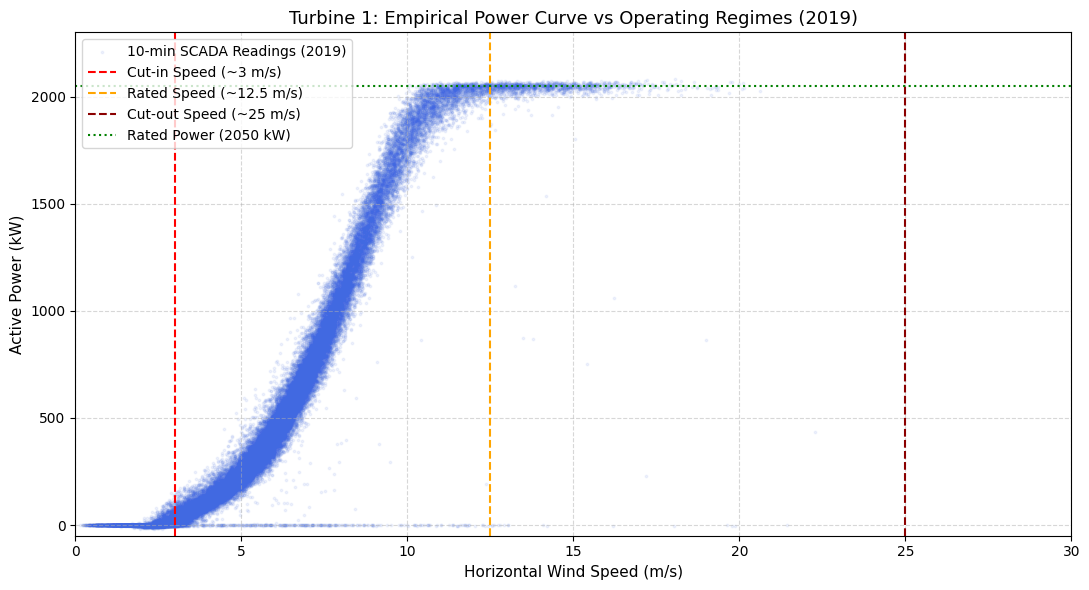

In [15]:
import matplotlib.pyplot as plt

# 1. Relevant columns pick karein
wind_col = 'Wind speed (m/s)'
power_col = 'Power (kW)'

# 2. Numeric conversion ensure karein
df_t1[wind_col] = pd.to_numeric(df_t1[wind_col], errors='coerce')
df_t1[power_col] = pd.to_numeric(df_t1[power_col], errors='coerce')

# 3. Power Curve plot karein
plt.figure(figsize=(11, 6))

# SCADA observations scatter
plt.scatter(
    df_t1[wind_col],
    df_t1[power_col],
    alpha=0.08,
    s=3,
    c='royalblue',
    label='10-min SCADA Readings (2019)'
)

# Senvion MM92 operational reference lines
plt.axvline(3.0, color='red', linestyle='--', linewidth=1.5, label='Cut-in Speed (~3 m/s)')
plt.axvline(12.5, color='orange', linestyle='--', linewidth=1.5, label='Rated Speed (~12.5 m/s)')
plt.axvline(25.0, color='darkred', linestyle='--', linewidth=1.5, label='Cut-out Speed (~25 m/s)')
plt.axhline(2050, color='green', linestyle=':', linewidth=1.5, label='Rated Power (2050 kW)')

plt.title('Turbine 1: Empirical Power Curve vs Operating Regimes (2019)', fontsize=13)
plt.xlabel('Horizontal Wind Speed (m/s)', fontsize=11)
plt.ylabel('Active Power (kW)', fontsize=11)
plt.xlim(0, 30)
plt.ylim(-50, 2300)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

pd.to_numeric(..., errors='coerce'): Agar koi reading corrupted string ya NaN ho, toh woh smoothly float ban jayegi.plt.scatter(..., alpha=0.08): $52,560$ points ko high-transparency (alpha) ke saath plot kar rahe hain taaki jahan points dense hain (normal operation) woh dark blue dikhe, aur jo unusual/fault points hain woh alag se isolate ho kar dikhein.   Operational markers (~3 m/s par turbine start, ~12.5 m/s par rated plateau 2050 kW) directly verify karenge ki turbine aerodynamic standards follow kar rahi hai ya nahi

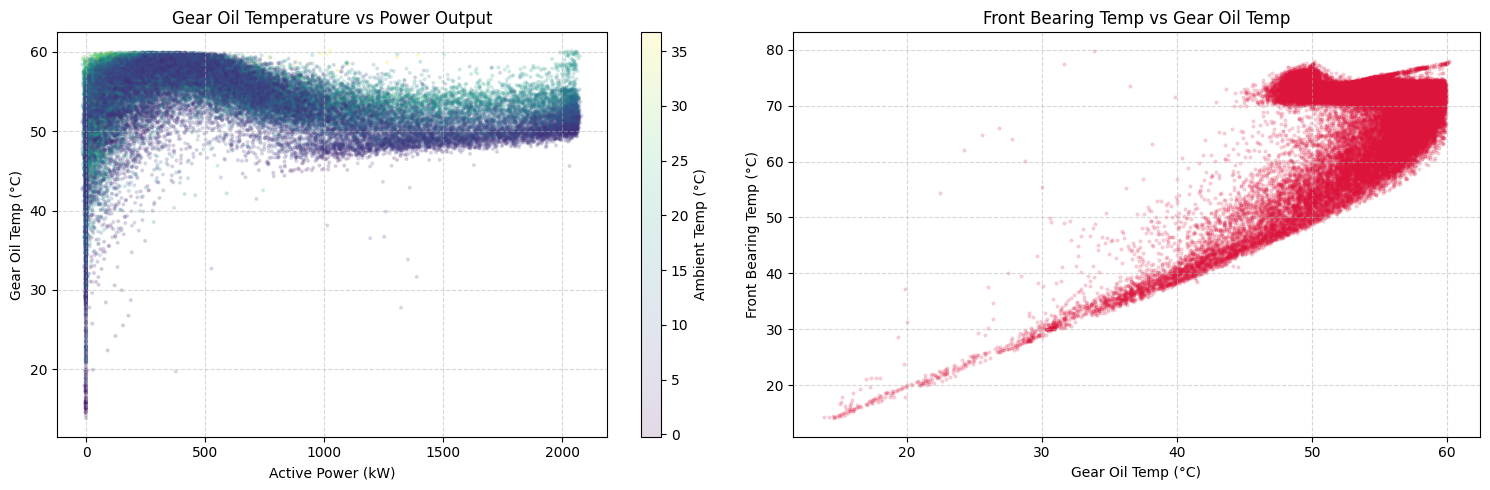

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Thermal aur ambient columns pick karein
gear_temp_col = 'Gear oil temperature (°C)'
bearing_temp_col = 'Front bearing temperature (°C)'
ambient_temp_col = 'Nacelle ambient temperature (°C)'
power_col = 'Power (kW)'

# Numeric clean
for c in [gear_temp_col, bearing_temp_col, ambient_temp_col]:
    df_t1[c] = pd.to_numeric(df_t1[c], errors='coerce')

# 2. Temperature vs Power Relationship Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot A: Gear Oil Temp vs Active Power
scatter1 = axes[0].scatter(
    df_t1[power_col],
    df_t1[gear_temp_col],
    c=df_t1[ambient_temp_col],
    cmap='viridis',
    alpha=0.15,
    s=4
)
axes[0].set_title('Gear Oil Temperature vs Power Output')
axes[0].set_xlabel('Active Power (kW)')
axes[0].set_ylabel('Gear Oil Temp (°C)')
axes[0].grid(True, linestyle='--', alpha=0.5)
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Ambient Temp (°C)')

# Plot B: Bearing Temp vs Gear Oil Temp (Coupling check)
scatter2 = axes[1].scatter(
    df_t1[gear_temp_col],
    df_t1[bearing_temp_col],
    alpha=0.15,
    s=4,
    c='crimson'
)
axes[1].set_title('Front Bearing Temp vs Gear Oil Temp')
axes[1].set_xlabel('Gear Oil Temp (°C)')
axes[1].set_ylabel('Front Bearing Temp (°C)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Plot A (Gear Oil vs Power with Ambient color):Bijli (kW) badhne par mechanical load badhta hai, toh oil ka garam hona normal hai.c=df_t1[ambient_temp_col]: Yeh har point ko mausam ke hisaab se rang dega (thande dino mein purple/blue, garm dino mein yellow/green).Key insight jo hum dhoondh rahe hain: Agar kam power ($< 500\text{ kW}$) par bhi oil temperature achanak $65^\circ\text{C}$ cross kar raha hai, toh woh cooling system failure ya pump issue ka clear precursor signal hota hai.   Plot B (Bearing vs Gearbox):Dono drive-train components ek doosre ke sath physically jude hote hain. Inka strong positive correlation baseline banayega. Agar points is straight diagonal line se bhatak rahe hain, toh particular bearing mein localized friction hai.

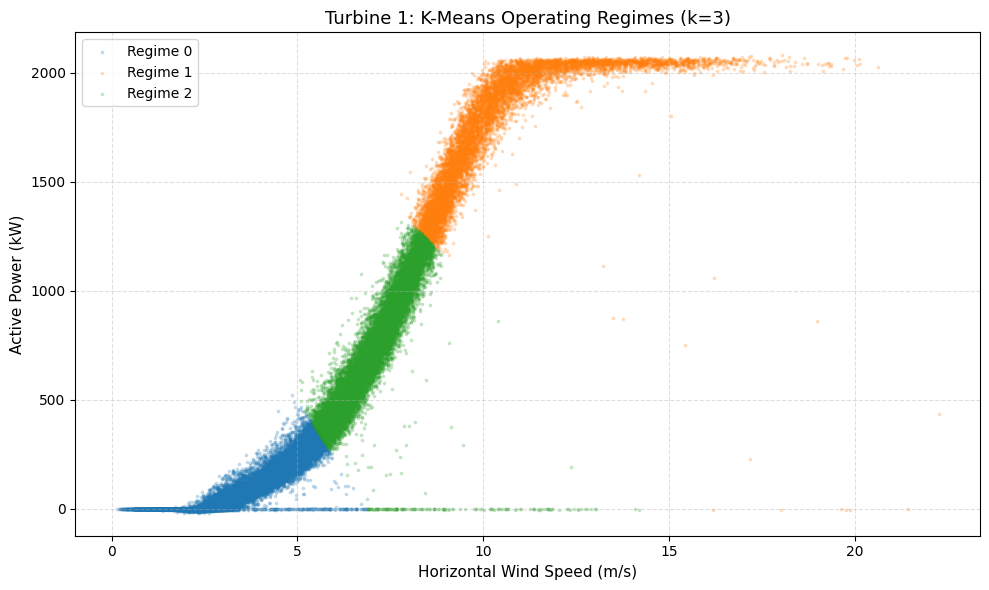


--- Regimes Summary Statistics ---


Wind speed (m/s)               Power (kW)                         
                    min   mean    max        min     mean      max  count
Regime                                                                   
0                  0.13   3.83   6.87     -17.85   126.88   523.57  24209
1                  7.79  10.44  22.27      -3.65  1728.71  2081.03   8863
2                  5.08   6.87  14.20      -6.23   686.80  1314.73  19404

In [17]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Clustering ke liye features pick karein
features = ['Wind speed (m/s)', 'Power (kW)']
cluster_df = df_t1[features].dropna().copy()

# 2. Features ko scale karein (Z-score normalization)
# Wind speed (0-25) aur Power (0-2050) ke scales alag hain, isliye scaling zaroori hai
scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_df)

# 3. K-Means algorithm run karein (k=3 regimes)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_df['Regime'] = kmeans.fit_predict(scaled_features)

# 4. Result ko visualize karein
plt.figure(figsize=(10, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for cluster_id, color in zip(sorted(cluster_df['Regime'].unique()), colors):
    subset = cluster_df[cluster_df['Regime'] == cluster_id]
    plt.scatter(
        subset['Wind speed (m/s)'],
        subset['Power (kW)'],
        s=3,
        alpha=0.2,
        c=color,
        label=f'Regime {cluster_id}'
    )

plt.title('Turbine 1: K-Means Operating Regimes (k=3)', fontsize=13)
plt.xlabel('Horizontal Wind Speed (m/s)', fontsize=11)
plt.ylabel('Active Power (kW)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Har regime ka summary stats dekhein
print("\n--- Regimes Summary Statistics ---")
summary = cluster_df.groupby('Regime').agg({
    'Wind speed (m/s)': ['min', 'mean', 'max'],
    'Power (kW)': ['min', 'mean', 'max', 'count']
}).round(2)
display(summary)

Found Hydraulic Fault Events:


,Timestamp start,Timestamp end,Message,Status
527,2019-02-24 02:31:49,2019-02-24 02:39:36,Low hydraulic pressure,Stop
1056,2019-03-27 20:32:14,2019-03-27 20:40:36,Low hydraulic pressure,Stop



Analyzing precursor window around: 2019-02-24 02:31:49


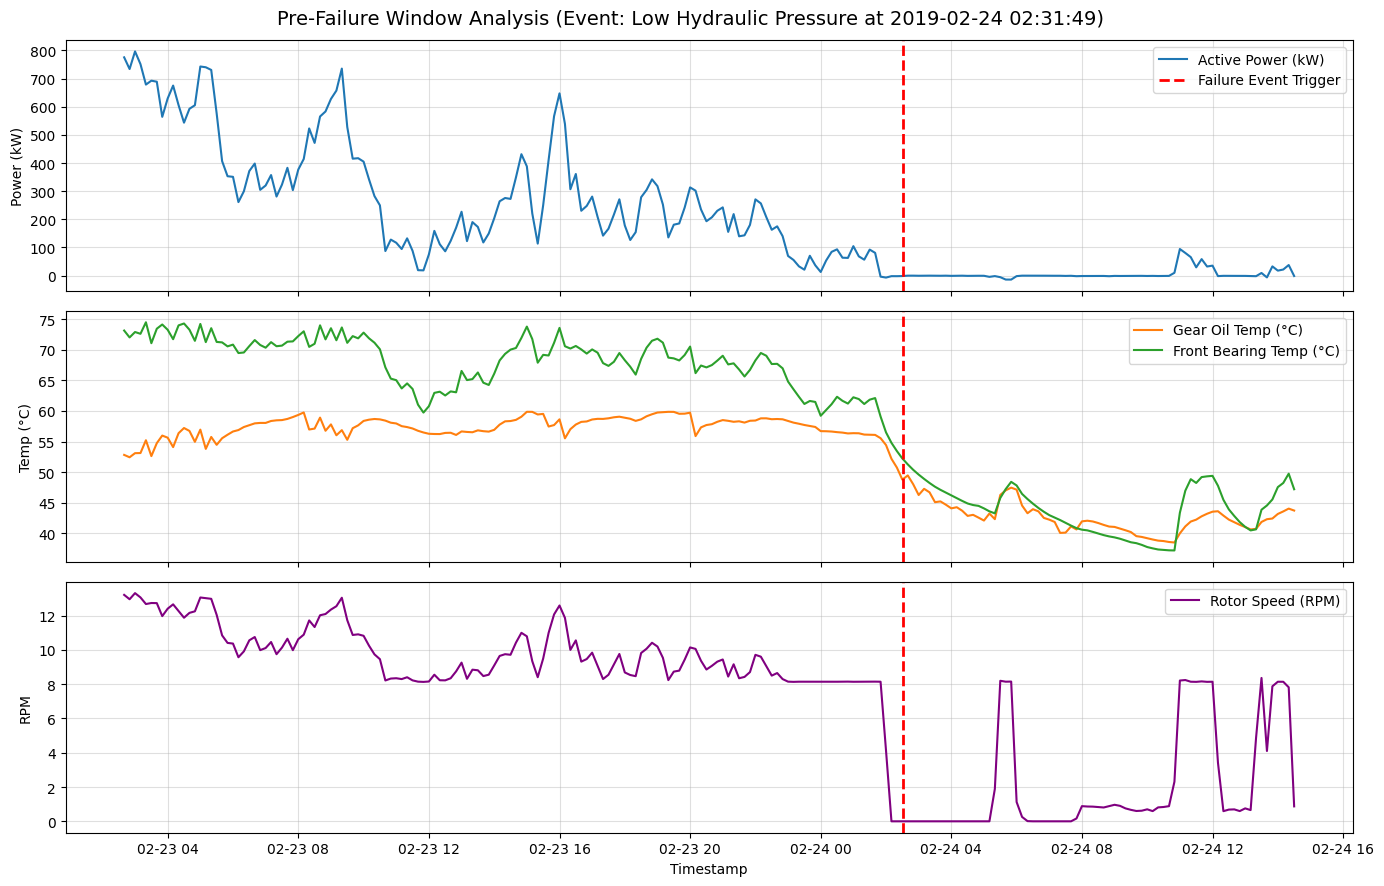

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Status log se hydraulic pressure failure ka exact timestamp nikalte hain
fault_events = df_status[df_status['Message'].str.contains('hydraulic pressure', case=False, na=False)]
print("Found Hydraulic Fault Events:")
display(fault_events[['Timestamp start', 'Timestamp end', 'Message', 'Status']])

# 2. Pehla fault timestamp pick karte hain
target_time = pd.to_datetime(fault_events.iloc[0]['Timestamp start'])
print(f"\nAnalyzing precursor window around: {target_time}")

# 3. Fault se 24 ghante pehle aur 12 ghante baad ka SCADA slice cut karein
start_window = target_time - pd.Timedelta(hours=24)
end_window = target_time + pd.Timedelta(hours=12)

scada_window = df_t1[(df_t1['Date and time'] >= start_window) & (df_t1['Date and time'] <= end_window)].copy()

# 4. Multi-sensor Precursor Trend Plot karein
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# Graph 1: Power vs Wind
axes[0].plot(scada_window['Date and time'], scada_window['Power (kW)'], color='tab:blue', label='Active Power (kW)')
axes[0].set_ylabel('Power (kW)')
axes[0].axvline(target_time, color='red', linestyle='--', linewidth=2, label='Failure Event Trigger')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.4)

# Graph 2: Gear Oil & Bearing Temperatures
axes[1].plot(scada_window['Date and time'], scada_window['Gear oil temperature (°C)'], color='tab:orange', label='Gear Oil Temp (°C)')
axes[1].plot(scada_window['Date and time'], scada_window['Front bearing temperature (°C)'], color='tab:green', label='Front Bearing Temp (°C)')
axes[1].set_ylabel('Temp (°C)')
axes[1].axvline(target_time, color='red', linestyle='--', linewidth=2)
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.4)

# Graph 3: Rotor / Generator RPM
axes[2].plot(scada_window['Date and time'], scada_window['Rotor speed (RPM)'], color='purple', label='Rotor Speed (RPM)')
axes[2].set_ylabel('RPM')
axes[2].axvline(target_time, color='red', linestyle='--', linewidth=2)
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.4)

plt.suptitle(f'Pre-Failure Window Analysis (Event: Low Hydraulic Pressure at {target_time})', fontsize=14)
plt.xlabel('Timestamp')
plt.tight_layout()
plt.show()

--- Missing Values Percentage per Sensor ---
Wind speed (m/s)                            0.16
Power (kW)                                  0.16
Blade angle (pitch position) A (°)          4.62
Rotor speed (RPM)                           0.16
Generator RPM (RPM)                         0.16
Gear oil temperature (°C)                   4.62
Front bearing temperature (°C)              4.62
Generator bearing front temperature (°C)    0.16
Stator temperature 1 (°C)                   0.16
Transformer temperature (°C)                4.62
Nacelle ambient temperature (°C)            4.62
Gear oil inlet pressure (bar)               0.16
Tower Acceleration X (mm/ss)                4.62
dtype: float64


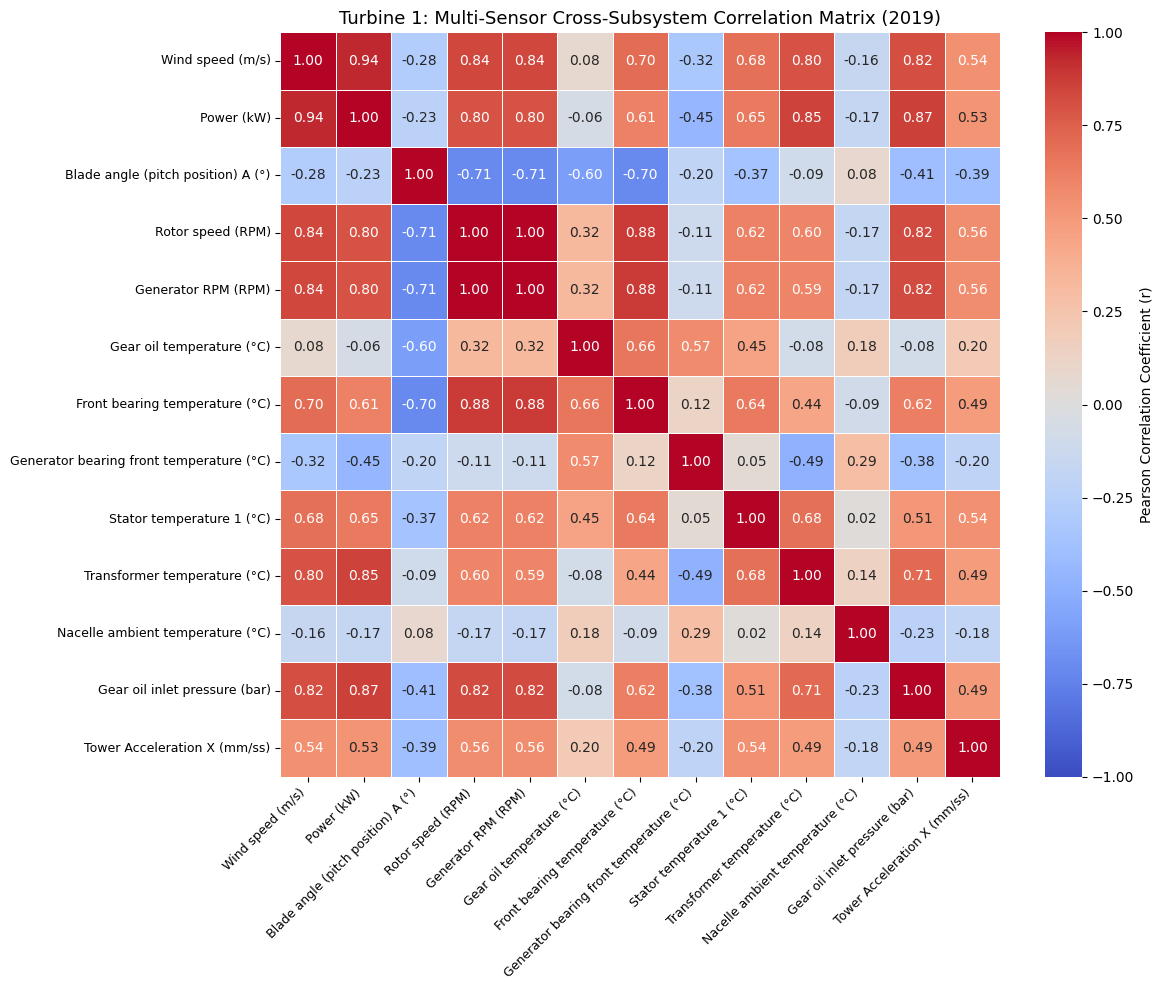

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Core representative sensors select karein across all subsystems
core_sensors = [
    'Wind speed (m/s)',
    'Power (kW)',
    'Blade angle (pitch position) A (°)',
    'Rotor speed (RPM)',
    'Generator RPM (RPM)',
    'Gear oil temperature (°C)',
    'Front bearing temperature (°C)',
    'Generator bearing front temperature (°C)',
    'Stator temperature 1 (°C)',
    'Transformer temperature (°C)',
    'Nacelle ambient temperature (°C)',
    'Gear oil inlet pressure (bar)',
    'Tower Acceleration X (mm/ss)'
]

# 2. Columns filter karein aur numeric conversion ensure karein
df_corr_subset = df_t1[core_sensors].apply(pd.to_numeric, errors='coerce')

# Missing value density check before correlation
missing_summary = df_corr_subset.isnull().mean() * 100
print("--- Missing Values Percentage per Sensor ---")
print(missing_summary.round(2))

# 3. Pearson Correlation Matrix calculate karein
corr_matrix = df_corr_subset.corr(method='pearson')

# 4. Correlation Heatmap plot karein
plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient (r)'}
)
plt.title('Turbine 1: Multi-Sensor Cross-Subsystem Correlation Matrix (2019)', fontsize=13)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

--- 1. Cross-Validating Second Hydraulic Failure Event ---


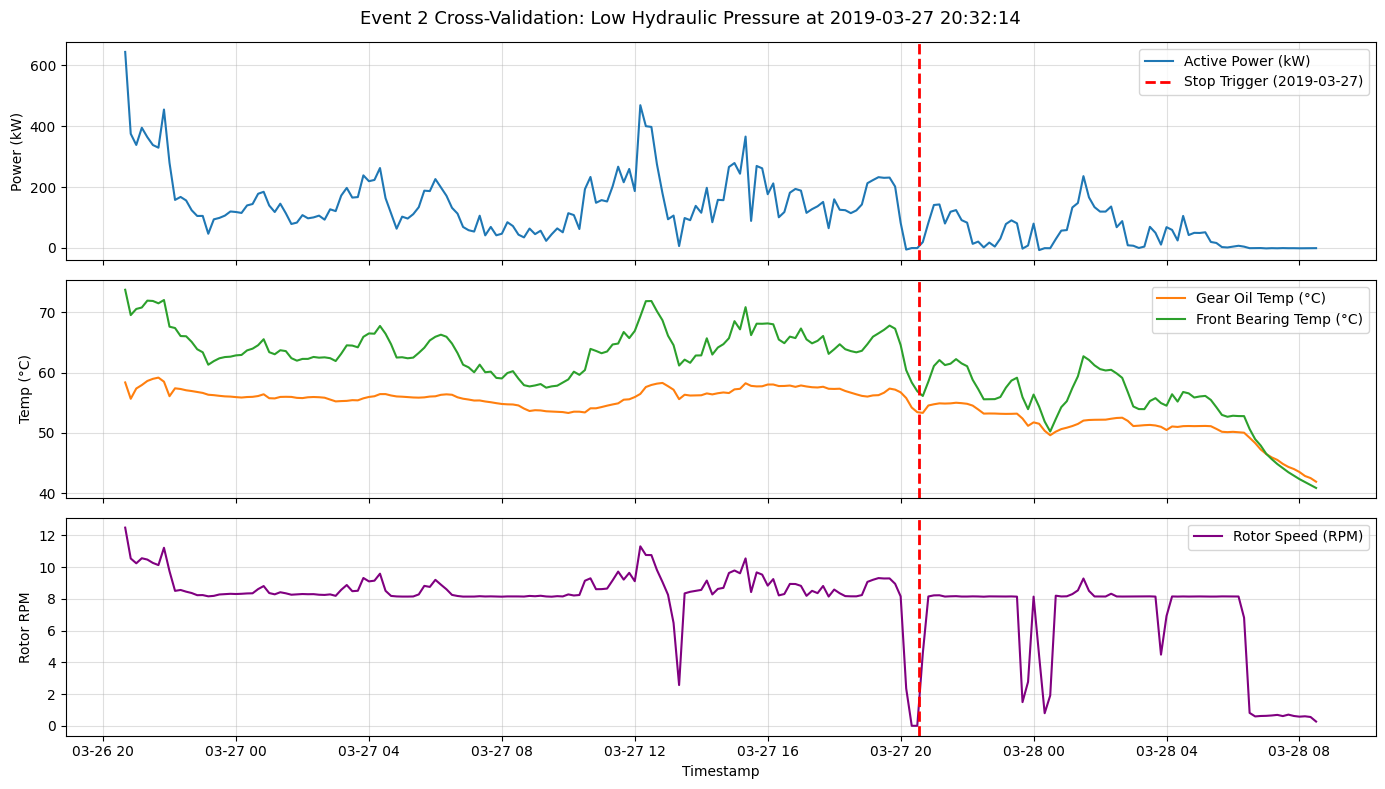


--- 2. Sensor Quality & Flatline Audit ---


,Sensor Channel,Missing / NaN (%),Zero Readings (%),Max Frozen Consecutive Steps
0,Wind speed (m/s),0.16,0.00,1
1,Power (kW),0.16,0.00,1
2,Rotor speed (RPM),0.16,2.17,48
3,Gear oil temperature (°C),4.62,0.00,1
4,Front bearing temperature (°C),4.62,0.00,9
5,Gear oil inlet pressure (bar),0.16,0.21,6
6,Tower Acceleration X (mm/ss),4.62,0.00,0


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. SECOND FAILURE EVENT CROSS-VALIDATION (2019-03-27)
# ---------------------------------------------------------
print("--- 1. Cross-Validating Second Hydraulic Failure Event ---")

# Second hydraulic event timestamp
target_time_2 = pd.to_datetime('2019-03-27 20:32:14')

# 24 hours prior, 12 hours after
start_win_2 = target_time_2 - pd.Timedelta(hours=24)
end_win_2 = target_time_2 + pd.Timedelta(hours=12)

# Ensure Date and time is datetime
df_t1['Date and time'] = pd.to_datetime(df_t1['Date and time'])

scada_win_2 = df_t1[(df_t1['Date and time'] >= start_win_2) & (df_t1['Date and time'] <= end_win_2)].copy()

# Plot multi-sensor behavior around second event
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# Power
axes[0].plot(scada_win_2['Date and time'], scada_win_2['Power (kW)'], color='tab:blue', label='Active Power (kW)')
axes[0].axvline(target_time_2, color='red', linestyle='--', linewidth=2, label='Stop Trigger (2019-03-27)')
axes[0].set_ylabel('Power (kW)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.4)

# Gear Oil & Bearing Temperatures
axes[1].plot(scada_win_2['Date and time'], scada_win_2['Gear oil temperature (°C)'], color='tab:orange', label='Gear Oil Temp (°C)')
axes[1].plot(scada_win_2['Date and time'], scada_win_2['Front bearing temperature (°C)'], color='tab:green', label='Front Bearing Temp (°C)')
axes[1].axvline(target_time_2, color='red', linestyle='--', linewidth=2)
axes[1].set_ylabel('Temp (°C)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.4)

# Rotor RPM & Inlet Pressure
axes[2].plot(scada_win_2['Date and time'], scada_win_2['Rotor speed (RPM)'], color='purple', label='Rotor Speed (RPM)')
axes[2].axvline(target_time_2, color='red', linestyle='--', linewidth=2)
axes[2].set_ylabel('Rotor RPM')
axes[2].legend(loc='upper right')
axes[2].grid(True, alpha=0.4)

plt.suptitle('Event 2 Cross-Validation: Low Hydraulic Pressure at 2019-03-27 20:32:14', fontsize=13)
plt.xlabel('Timestamp')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. SENSOR INTEGRITY & FROZEN / FLATLINE AUDIT
# ---------------------------------------------------------
print("\n--- 2. Sensor Quality & Flatline Audit ---")

core_channels = [
    'Wind speed (m/s)', 'Power (kW)', 'Rotor speed (RPM)',
    'Gear oil temperature (°C)', 'Front bearing temperature (°C)',
    'Gear oil inlet pressure (bar)', 'Tower Acceleration X (mm/ss)'
]

audit_records = []

for ch in core_channels:
    s = pd.to_numeric(df_t1[ch], errors='coerce')
    nan_pct = s.isnull().mean() * 100
    zero_pct = (s == 0).mean() * 100

    # Frozen check: consecutive identical values (> 6 consecutive 10-min readings = 1 hr flatline)
    diffs = s.diff().abs()
    frozen_runs = (diffs == 0).astype(int)
    max_consecutive_frozen = frozen_runs.groupby((frozen_runs != frozen_runs.shift()).cumsum()).cumsum().max()

    audit_records.append({
        'Sensor Channel': ch,
        'Missing / NaN (%)': round(nan_pct, 2),
        'Zero Readings (%)': round(zero_pct, 2),
        'Max Frozen Consecutive Steps': max_consecutive_frozen
    })

audit_df = pd.DataFrame(audit_records)
display(audit_df)

In [22]:
print(df_status.head(2))

       Timestamp start        Timestamp end  Duration         Status    Code  \
0  2019-01-01 11:03:12  2019-01-01 11:05:30  00:02:18           Stop     710   
1  2019-01-01 11:03:12                    -         -  Informational  100030   

             Message  Comment Service contract category       IEC category  
0       Battery test      NaN    Operating states  (28)  Technical Standby  
1  Brake program 180      NaN                       NaN  Technical Standby  


In [2]:
BASE = {
    'wind'      : 'Wind speed (m/s)',
    'power'     : 'Power (kW)',
    'pitch'     : 'Blade angle (pitch position) A (°)',
    'rotor'     : 'Rotor speed (RPM)',
    'gen_rpm'   : 'Generator RPM (RPM)',
    'gear_oil'  : 'Gear oil temperature (°C)',
    'front_brg' : 'Front bearing temperature (°C)',
    'gen_brg'   : 'Generator bearing front temperature (°C)',
    'stator'    : 'Stator temperature 1 (°C)',
    'trafo'     : 'Transformer temperature (°C)',
    'ambient'   : 'Nacelle ambient temperature (°C)',
    'oil_press' : 'Gear oil inlet pressure (bar)',
    'tower_acc' : 'Tower Acceleration X (mm/ss)',
}
absent = [v for v in BASE.values() if v not in df_t1.columns]
if absent:
    print("Ye columns file mein nahi mile, skip honge:", absent)
BASE = {k: v for k, v in BASE.items() if v in df_t1.columns}

df = df_t1[['Date and time'] + list(BASE.values())].copy()
df = df.drop_duplicates('Date and time').set_index('Date and time')
df = df.apply(pd.to_numeric, errors='coerce')
df.columns = [k for k, v in BASE.items()]          # short names

# Poori 10-min grid par reindex
full_idx = pd.date_range(df.index.min(), df.index.max(), freq='10min')
df = df.reindex(full_idx)
df.index.name = 'timestamp'
print("Rows after regular grid:", len(df))

# Sirf chhote gaps (<= 30 min) interpolate karein
print("\nMissing % before:"); print((df.isna().mean()*100).round(2).to_string())
df = df.interpolate(method='time', limit=3, limit_area='inside')

# Physically impossible values -> NaN
df.loc[df['wind'] < 0, 'wind'] = np.nan
df.loc[df['rotor'] < 0, 'rotor'] = np.nan

Rows after regular grid: 52560

Missing % before:
wind         0.16
power        0.16
pitch        4.62
rotor        0.16
gen_rpm      0.16
gear_oil     4.62
front_brg    4.62
gen_brg      0.16
stator       0.16
trafo        4.62
ambient      4.62
oil_press    0.16
tower_acc    4.62


In [3]:
import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
warnings.filterwarnings("ignore")

# Colab ho to Drive mount, warna local folder (LOCAL_DIR badlein agar zaroori ho)
LOCAL_DIR = r"C:\Users\Bmu\WindGuard-Wind-Turbine-Failure-Precursor-Detection"
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = "/content/drive/MyDrive/WindGuard_Project"
except ImportError:
    BASE_DIR = LOCAL_DIR
print("Base dir:", BASE_DIR, "| exists:", os.path.isdir(BASE_DIR))

def find(pattern):
    return sorted(glob.glob(os.path.join(BASE_DIR, "**", pattern), recursive=True))

# Zip hai aur CSV nahi mili to extract
if not find("Turbine_Data_Kelmarsh_1_2019*.csv"):
    for z in find("Kelmarsh_SCADA_2019*.zip"):
        out = os.path.join(BASE_DIR, "extracted_scada_2019")
        print("Extracting", z)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(out)

scada_hits  = find("Turbine_Data_Kelmarsh_1_2019*.csv")
status_hits = find("Status_Kelmarsh_1_2019*.csv")
if not scada_hits or not status_hits:
    raise FileNotFoundError(
        f"SCADA/Status CSV '{BASE_DIR}' ke andar nahi mili. "
        "LOCAL_DIR sahi folder par set karein ya zip us folder mein rakhein.\n"
        f"Folder ke CSV/zip: {[os.path.basename(p) for p in find('*.csv') + find('*.zip')][:15]}")
scada_file, status_file = scada_hits[0], status_hits[0]
print("SCADA :", scada_file)
print("STATUS:", status_file)

# Greenbyte CSV reader: header row auto-detect
def read_greenbyte(path):
    for enc in ("utf-8", "latin-1"):
        try:
            with open(path, encoding=enc) as f:
                head = [f.readline() for _ in range(60)]
            break
        except UnicodeDecodeError:
            continue
    hdr = next(i for i, l in enumerate(head) if l.count(",") >= 3)
    d = pd.read_csv(path, skiprows=hdr, encoding=enc, low_memory=False, skipinitialspace=True)
    d.columns = [c.replace("# ", "").replace("Â°", "°").strip() for c in d.columns]
    return d

df_t1 = read_greenbyte(scada_file)
df_t1['Date and time'] = pd.to_datetime(df_t1['Date and time'])
df_t1 = df_t1.sort_values('Date and time').reset_index(drop=True)

df_status = read_greenbyte(status_file)

print("\nSCADA  :", df_t1.shape, "|", df_t1['Date and time'].min(), "->", df_t1['Date and time'].max())
print("STATUS :", df_status.shape, "| columns:", list(df_status.columns))
display(df_t1.iloc[:3, :6])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base dir: /content/drive/MyDrive/WindGuard_Project | exists: True
SCADA : /content/drive/MyDrive/WindGuard_Project/extracted_scada_2019/Turbine_Data_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv
STATUS: /content/drive/MyDrive/WindGuard_Project/extracted_scada_2019/Status_Kelmarsh_1_2019-01-01_-_2020-01-01_228.csv

SCADA  : (52560, 299) | 2019-01-01 00:00:00 -> 2019-12-31 23:50:00
STATUS : (7821, 9) | columns: ['Timestamp start', 'Timestamp end', 'Duration', 'Status', 'Code', 'Message', 'Comment', 'Service contract category', 'IEC category']


,Date and time,Wind speed (m/s),"Wind speed, Standard deviation (m/s)","Wind speed, Minimum (m/s)","Wind speed, Maximum (m/s)",Long Term Wind (m/s)
0,2019-01-01 00:00:00,4.454060,0.943410,1.921281,7.008520,7.1
1,2019-01-01 00:10:00,4.331436,0.855507,3.002733,5.962338,7.1
2,2019-01-01 00:20:00,5.447210,0.821944,4.114998,6.851853,7.1


In [3]:
feat = pd.DataFrame(index=df.index)

# ---- raw sensors
for c in BASE:
    feat[c] = df[c]

# ---- A. Power curve deviation
bins = np.arange(0, 25.5, 0.5)
tr = df.loc[base_train, ['wind', 'power']].dropna()
tr['bin'] = pd.cut(tr['wind'], bins)
curve = tr.groupby('bin', observed=True).agg(w=('wind', 'median'), p=('power', 'median')).dropna()
expected_power = np.interp(df['wind'], curve['w'], curve['p'])
expected_power = pd.Series(expected_power, index=df.index).where(df['wind'].notna())
feat['power_dev']   = df['power'] - expected_power
feat['power_ratio'] = df['power'] / expected_power.clip(lower=50)
feat.loc[expected_power < 50, 'power_ratio'] = np.nan

# ---- B. Thermal residual models (normal train rows par fit)
df['power_sq'] = df['power'] ** 2 / 1e3
PRED = ['power', 'power_sq', 'ambient', 'rotor']

def thermal_residual(target):
    d = df.loc[base_train, PRED + [target]].dropna()
    m = Ridge(alpha=1.0).fit(d[PRED], d[target])
    ok = df[PRED].notna().all(axis=1)
    pred = pd.Series(np.nan, index=df.index)
    pred[ok] = m.predict(df.loc[ok, PRED])
    return df[target] - pred

for t in ['gear_oil', 'front_brg', 'gen_brg', 'stator']:
    if t in df.columns:
        feat[f'{t}_res'] = thermal_residual(t)

# ---- C. Differentials & ratios
feat['gear_minus_amb']      = df['gear_oil']  - df['ambient']
feat['frontbrg_minus_amb']  = df['front_brg'] - df['ambient']
feat['genbrg_minus_gear']   = df['gen_brg']   - df['gear_oil']
feat['stator_minus_amb']    = df['stator']    - df['ambient']
feat['trafo_minus_amb']     = df['trafo']     - df['ambient']
feat['gear_minus_frontbrg'] = df['gear_oil']  - df['front_brg']
feat['rpm_ratio'] = (df['gen_rpm'] / df['rotor']).where(df['rotor'] > 1)

# ---- D. Rolling statistics (trailing only -> no future leakage)
WINDOWS = {'1h': 6, '6h': 36, '24h': 144}
ROLL_SIGNALS = [c for c in ['power_dev', 'gear_oil_res', 'front_brg_res', 'gen_brg_res', 'stator_res',
                            'oil_press', 'tower_acc', 'pitch', 'rpm_ratio'] if c in feat.columns]
for s in ROLL_SIGNALS:
    for name, w in WINDOWS.items():
        r = feat[s].rolling(w, min_periods=max(2, w // 2))
        feat[f'{s}_mean_{name}'] = r.mean()
        feat[f'{s}_std_{name}']  = r.std()
for s in [c for c in ['gear_oil_res', 'front_brg_res', 'gen_brg_res', 'stator_res', 'power_dev'] if c in feat.columns]:
    feat[f'{s}_trend_6h'] = feat[f'{s}_mean_1h'].diff(36)

# ---- E. Time features (PCA mein use nahi honge)
hour  = feat.index.hour + feat.index.minute / 60
month = feat.index.month
feat['hour_sin']  = np.sin(2 * np.pi * hour / 24)
feat['hour_cos']  = np.cos(2 * np.pi * hour / 24)
feat['month_sin'] = np.sin(2 * np.pi * month / 12)
feat['month_cos'] = np.cos(2 * np.pi * month / 12)

# ---- labels attach
for c in ['precursor', 'fault_active', 'operating']:
    feat[c] = df[c]

print("Total engineered table:", feat.shape)
feat.drop(columns=['precursor', 'fault_active', 'operating']).describe().T.head(15)

In [7]:
# 1. Define active operating state, fault periods, and precursor windows
hydraulic_faults = [
    pd.to_datetime('2019-02-24 02:31:49'),
    pd.to_datetime('2019-03-27 20:32:14')
]

df['fault_active'] = 0
df['precursor'] = 0

for f_time in hydraulic_faults:
    precursor_start = f_time - pd.Timedelta(hours=24)
    df.loc[(df.index >= precursor_start) & (df.index < f_time), 'precursor'] = 1
    df.loc[(df.index >= f_time) & (df.index <= f_time + pd.Timedelta(hours=2)), 'fault_active'] = 1

df['operating'] = 1
df.loc[df['fault_active'] == 1, 'operating'] = 0
df.loc[(df['wind'] > 3.0) & (df['power'] <= 0) & (df['rotor'] < 1), 'operating'] = 0

split_time = pd.to_datetime('2019-09-01 00:00:00')
base_train = df.index < split_time

# 2. Build engineered features table
feat = pd.DataFrame(index=df.index)
for c in BASE:
    feat[c] = df[c]

# Power curve deviation
bins = np.arange(0, 25.5, 0.5)
tr = df.loc[base_train, ['wind', 'power']].dropna()
tr['bin'] = pd.cut(tr['wind'], bins)
curve = tr.groupby('bin', observed=True).agg(w=('wind', 'median'), p=('power', 'median')).dropna()
expected_power = np.interp(df['wind'], curve['w'], curve['p'])
expected_power = pd.Series(expected_power, index=df.index).where(df['wind'].notna())
feat['power_dev']   = df['power'] - expected_power
feat['power_ratio'] = df['power'] / expected_power.clip(lower=50)
feat.loc[expected_power < 50, 'power_ratio'] = np.nan

# Thermal residual models
df['power_sq'] = df['power'] ** 2 / 1e3
PRED = ['power', 'power_sq', 'ambient', 'rotor']

def thermal_residual(target):
    d = df.loc[base_train, PRED + [target]].dropna()
    m = Ridge(alpha=1.0).fit(d[PRED], d[target])
    ok = df[PRED].notna().all(axis=1)
    pred = pd.Series(np.nan, index=df.index)
    pred[ok] = m.predict(df.loc[ok, PRED])
    return df[target] - pred

for t in ['gear_oil', 'front_brg', 'gen_brg', 'stator']:
    if t in df.columns:
        feat[f'{t}_res'] = thermal_residual(t)

# Differentials & ratios
feat['gear_minus_amb']      = df['gear_oil']  - df['ambient']
feat['frontbrg_minus_amb']  = df['front_brg'] - df['ambient']
feat['genbrg_minus_gear']   = df['gen_brg']   - df['gear_oil']
feat['stator_minus_amb']    = df['stator']    - df['ambient']
feat['trafo_minus_amb']     = df['trafo']     - df['ambient']
feat['gear_minus_frontbrg'] = df['gear_oil']  - df['front_brg']
feat['rpm_ratio'] = (df['gen_rpm'] / df['rotor']).where(df['rotor'] > 1)

# Rolling statistics
WINDOWS = {'1h': 6, '6h': 36, '24h': 144}
ROLL_SIGNALS = [c for c in ['power_dev', 'gear_oil_res', 'front_brg_res', 'gen_brg_res', 'stator_res',
                            'oil_press', 'tower_acc', 'pitch', 'rpm_ratio'] if c in feat.columns]
for s in ROLL_SIGNALS:
    for name, w in WINDOWS.items():
        r = feat[s].rolling(w, min_periods=max(2, w // 2))
        feat[f'{s}_mean_{name}'] = r.mean()
        feat[f'{s}_std_{name}']  = r.std()
for s in [c for c in ['gear_oil_res', 'front_brg_res', 'gen_brg_res', 'stator_res', 'power_dev'] if c in feat.columns]:
    feat[f'{s}_trend_6h'] = feat[f'{s}_mean_1h'].diff(36)

# Time features
hour  = feat.index.hour + feat.index.minute / 60
month = feat.index.month
feat['hour_sin']  = np.sin(2 * np.pi * hour / 24)
feat['hour_cos']  = np.cos(2 * np.pi * hour / 24)
feat['month_sin'] = np.sin(2 * np.pi * month / 12)
feat['month_cos'] = np.cos(2 * np.pi * month / 12)

# Attach labels
for c in ['precursor', 'fault_active', 'operating']:
    feat[c] = df[c]

# 3. Model DataFrame and PCA Pre-processing
EXCLUDE = ['precursor', 'fault_active', 'operating', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
cand = [c for c in feat.columns if c not in EXCLUDE]

model_df = feat[feat['operating'] == 1].dropna(subset=cand).copy()
print("Rows after operating filter + dropna:", len(model_df), "/", len(feat))

is_train  = model_df.index < split_time
is_normal = (model_df['precursor'] == 0) & (model_df['fault_active'] == 0)
fit_mask  = is_train & is_normal
print("PCA fit rows (train + normal):", int(fit_mask.sum()))

X_fit = model_df.loc[fit_mask, cand]

# near-constant drop
low_var = X_fit.columns[X_fit.std() < 1e-8].tolist()
# high-correlation drop (|r| > 0.98)
corr  = X_fit.drop(columns=low_var).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = [c for c in upper.columns if (upper[c] > 0.98).any()]
FEATURES = [c for c in cand if c not in low_var + high_corr]
print(f"Features: {len(cand)} -> {len(FEATURES)}  (low-var dropped: {len(low_var)}, corr dropped: {len(high_corr)})")

scaler = StandardScaler().fit(model_df.loc[fit_mask, FEATURES])
Z_all  = pd.DataFrame(scaler.transform(model_df[FEATURES]), index=model_df.index, columns=FEATURES)
Z_fit  = Z_all[fit_mask]

Rows after operating filter + dropna: 41532 / 52560
PCA fit rows (train + normal): 26385
Features: 85 -> 84  (low-var dropped: 0, corr dropped: 1)


In [9]:
# 1. Define active operating state, fault periods, and precursor windows
# Let's define target_time for the hydraulic faults we discovered earlier
hydraulic_faults = [
    pd.to_datetime('2019-02-24 02:31:49'),
    pd.to_datetime('2019-03-27 20:32:14')
]

df['fault_active'] = 0
df['precursor'] = 0

# Mark fault periods (e.g., 2 hours starting from the trigger)
# and precursor windows (e.g., 24 hours before the fault starts)
for f_time in hydraulic_faults:
    # 24 hours prior precursor
    precursor_start = f_time - pd.Timedelta(hours=24)
    df.loc[(df.index >= precursor_start) & (df.index < f_time), 'precursor'] = 1
    # 2 hours active downtime
    df.loc[(df.index >= f_time) & (df.index <= f_time + pd.Timedelta(hours=2)), 'fault_active'] = 1

# Operating represents times where the turbine is producing power normally when wind is sufficient
df['operating'] = 1
df.loc[df['fault_active'] == 1, 'operating'] = 0
# If turbine is stopped / rotor speed is extremely low despite wind, not operating
df.loc[(df['wind'] > 3.0) & (df['power'] <= 0) & (df['rotor'] < 1), 'operating'] = 0

# Define training/split setup
split_time = pd.to_datetime('2019-09-01 00:00:00')
base_train = df.index < split_time

# 2. Build engineered features table
feat = pd.DataFrame(index=df.index)
for c in BASE:
    feat[c] = df[c]

# Power curve deviation
bins = np.arange(0, 25.5, 0.5)
tr = df.loc[base_train, ['wind', 'power']].dropna()
tr['bin'] = pd.cut(tr['wind'], bins)
curve = tr.groupby('bin', observed=True).agg(w=('wind', 'median'), p=('power', 'median')).dropna()
expected_power = np.interp(df['wind'], curve['w'], curve['p'])
expected_power = pd.Series(expected_power, index=df.index).where(df['wind'].notna())
feat['power_dev']   = df['power'] - expected_power
feat['power_ratio'] = df['power'] / expected_power.clip(lower=50)
feat.loc[expected_power < 50, 'power_ratio'] = np.nan

# Thermal residual models
df['power_sq'] = df['power'] ** 2 / 1e3
PRED = ['power', 'power_sq', 'ambient', 'rotor']

def thermal_residual(target):
    d = df.loc[base_train, PRED + [target]].dropna()
    m = Ridge(alpha=1.0).fit(d[PRED], d[target])
    ok = df[PRED].notna().all(axis=1)
    pred = pd.Series(np.nan, index=df.index)
    pred[ok] = m.predict(df.loc[ok, PRED])
    return df[target] - pred

for t in ['gear_oil', 'front_brg', 'gen_brg', 'stator']:
    if t in df.columns:
        feat[f'{t}_res'] = thermal_residual(t)

# Differentials & ratios
feat['gear_minus_amb']      = df['gear_oil']  - df['ambient']
feat['frontbrg_minus_amb']  = df['front_brg'] - df['ambient']
feat['genbrg_minus_gear']   = df['gen_brg']   - df['gear_oil']
feat['stator_minus_amb']    = df['stator']    - df['ambient']
feat['trafo_minus_amb']     = df['trafo']     - df['ambient']
feat['gear_minus_frontbrg'] = df['gear_oil']  - df['front_brg']
feat['rpm_ratio'] = (df['gen_rpm'] / df['rotor']).where(df['rotor'] > 1)

# Rolling statistics
WINDOWS = {'1h': 6, '6h': 36, '24h': 144}
ROLL_SIGNALS = [c for c in ['power_dev', 'gear_oil_res', 'front_brg_res', 'gen_brg_res', 'stator_res',
                            'oil_press', 'tower_acc', 'pitch', 'rpm_ratio'] if c in feat.columns]
for s in ROLL_SIGNALS:
    for name, w in WINDOWS.items():
        r = feat[s].rolling(w, min_periods=max(2, w // 2))
        feat[f'{s}_mean_{name}'] = r.mean()
        feat[f'{s}_std_{name}']  = r.std()
for s in [c for c in ['gear_oil_res', 'front_brg_res', 'gen_brg_res', 'stator_res', 'power_dev'] if c in feat.columns]:
    feat[f'{s}_trend_6h'] = feat[f'{s}_mean_1h'].diff(36)

# Time features
hour  = feat.index.hour + feat.index.minute / 60
month = feat.index.month
feat['hour_sin']  = np.sin(2 * np.pi * hour / 24)
feat['hour_cos']  = np.cos(2 * np.pi * hour / 24)
feat['month_sin'] = np.sin(2 * np.pi * month / 12)
feat['month_cos'] = np.cos(2 * np.pi * month / 12)

# Attach labels
for c in ['precursor', 'fault_active', 'operating']:
    feat[c] = df[c]

print("Total engineered table:", feat.shape)

Total engineered table: (52560, 92)


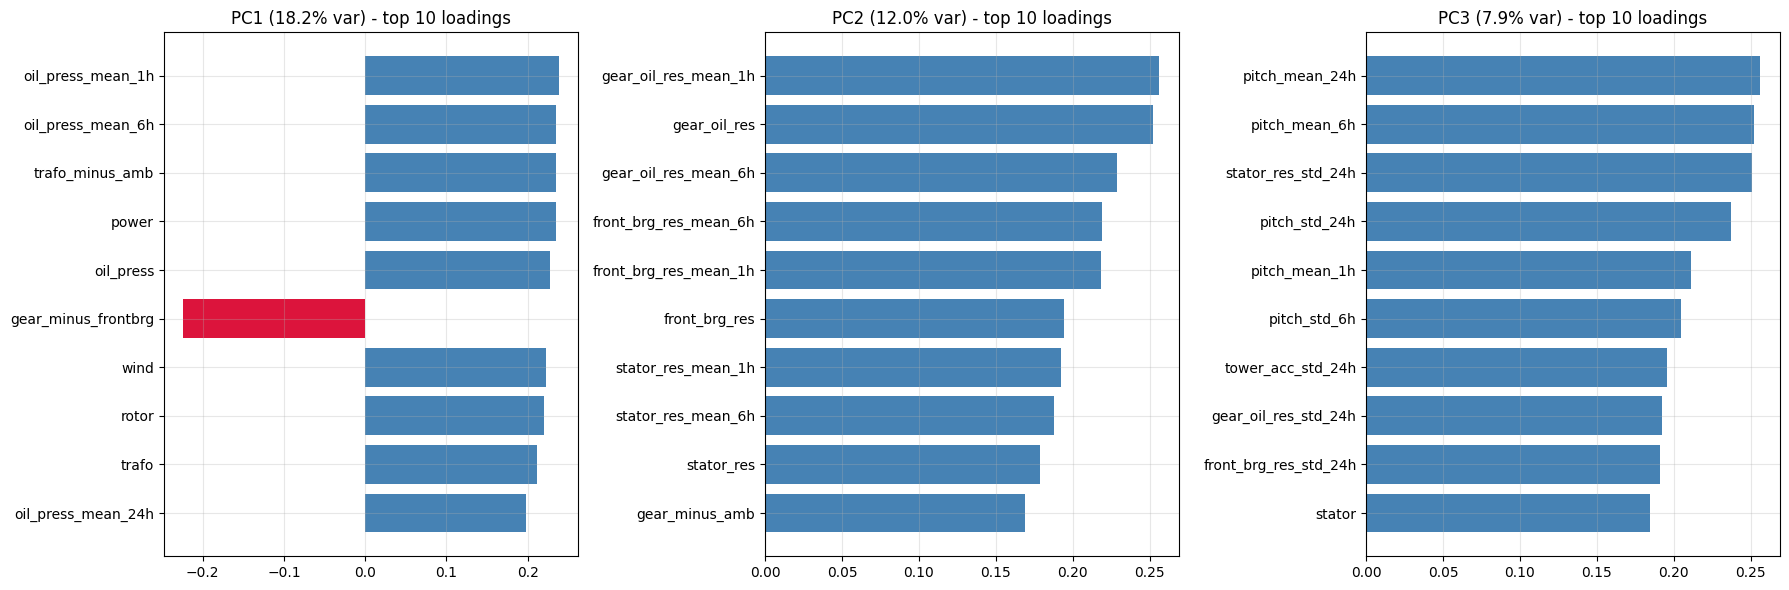

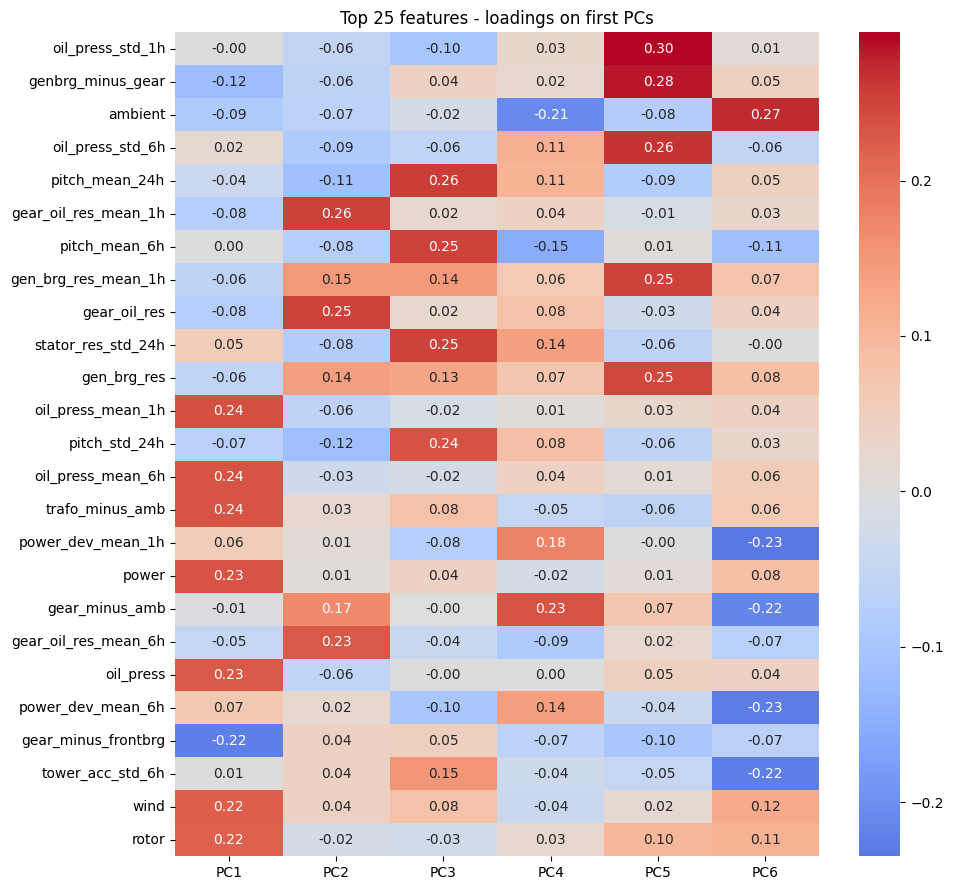

In [11]:
# Define the number of PCA components to keep
N_COMP = 6

# Initialize and fit PCA on training subset (Z_fit)
pca = PCA(n_components=N_COMP, random_state=42)
pca.fit(Z_fit)

# Project all operating normalized data (Z_all) into the principal component space
scores_data = pca.transform(Z_all)
scores = pd.DataFrame(
    scores_data,
    index=Z_all.index,
    columns=[f'PC{i+1}' for i in range(N_COMP)]
)

# Calculate principal component loadings
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=scores.columns)

# Plot top 10 feature loadings for the first 3 PCs
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, ax in enumerate(axes):
    pc = f'PC{i+1}'
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index)[:10][::-1]
    ax.barh(top.index, top.values, color=['crimson' if v < 0 else 'steelblue' for v in top.values])
    ax.set_title(f'{pc} ({pca.explained_variance_ratio_[i]*100:.1f}% var) - top 10 loadings')
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

# Heatmap of top 25 features across the first principal components
plt.figure(figsize=(10, 9))
sns.heatmap(loadings.iloc[:, :min(6, N_COMP)].loc[loadings.iloc[:, :6].abs().max(axis=1).sort_values(ascending=False).index[:25]],
            cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Top 25 features - loadings on first PCs')
plt.tight_layout()
plt.show()

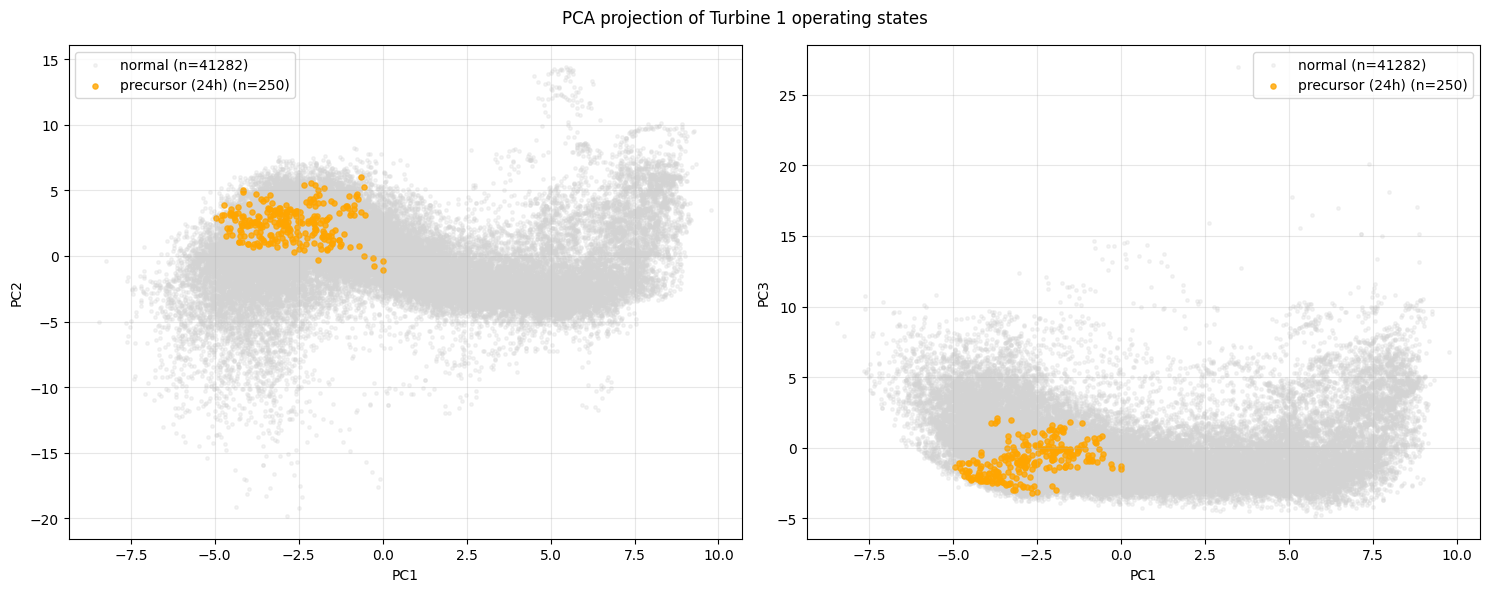

In [12]:
state = np.where(model_df['fault_active'] == 1, 'fault', np.where(model_df['precursor'] == 1, 'precursor (24h)', 'normal'))
colors = {'normal': 'lightgray', 'precursor (24h)': 'orange', 'fault': 'red'}

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for pcs, a in zip([('PC1', 'PC2'), ('PC1', 'PC3') if N_COMP > 2 else ('PC1', 'PC2')], ax):
    for s in ['normal', 'precursor (24h)', 'fault']:
        m = state == s
        if m.any():
            a.scatter(scores.loc[m, pcs[0]], scores.loc[m, pcs[1]], s=6 if s == 'normal' else 14,
                      alpha=.25 if s == 'normal' else .8, c=colors[s], label=f'{s} (n={m.sum()})')
    a.set_xlabel(pcs[0]); a.set_ylabel(pcs[1]); a.grid(alpha=.3); a.legend()
plt.suptitle('PCA projection of Turbine 1 operating states'); plt.tight_layout(); plt.show()

Alarm rate by state (%):
state
normal             1.48
precursor (24h)    0.00


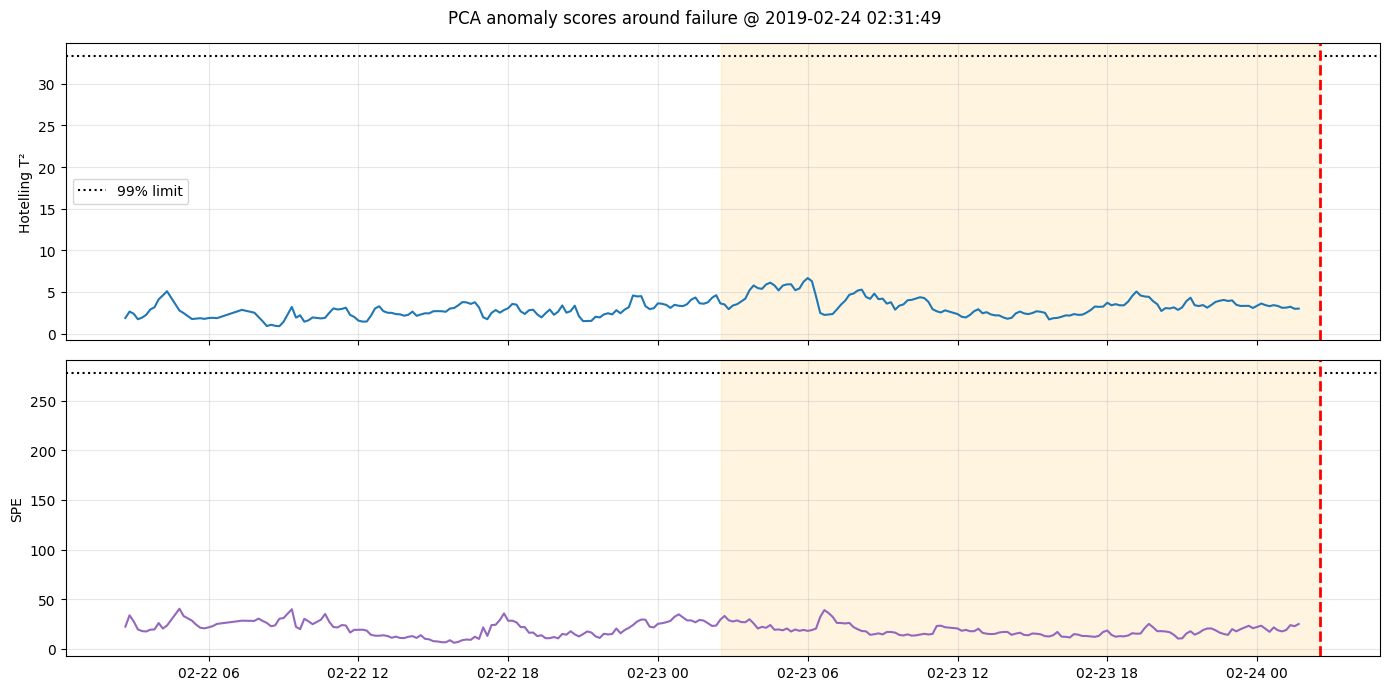

In [14]:
Zv = Z_all
S  = pca.transform(Zv)
Zv = Zv.values
recon = pca.inverse_transform(S)
spe = ((Zv - recon) ** 2).sum(axis=1)
t2  = ((S ** 2) / pca.explained_variance_).sum(axis=1)
anom = pd.DataFrame({'T2': t2, 'SPE': spe}, index=Z_all.index)

lim_t2  = np.percentile(anom.loc[fit_mask, 'T2'], 99)
lim_spe = np.percentile(anom.loc[fit_mask, 'SPE'], 99)
anom['alarm'] = ((anom['T2'] > lim_t2) | (anom['SPE'] > lim_spe)).astype(int)
anom['state'] = state

print("Alarm rate by state (%):")
print((anom.groupby('state')['alarm'].mean() * 100).round(2).to_string())

# Define ev and PRECURSOR_HOURS to resolve the NameError
PRECURSOR_HOURS = 24
ev = pd.DataFrame({'t_start': hydraulic_faults})

# Pehle failure event ke aas-paas plot
if len(ev):
    t0 = ev.iloc[0]['t_start']
    w = anom[(anom.index >= t0 - pd.Timedelta(hours=48)) & (anom.index <= t0 + pd.Timedelta(hours=12))]
    fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    ax[0].plot(w.index, w['T2'], color='tab:blue')
    ax[0].axhline(lim_t2, color='k', ls=':', label='99% limit')
    ax[0].set_ylabel('Hotelling T²')

    ax[1].plot(w.index, w['SPE'], color='tab:purple')
    ax[1].axhline(lim_spe, color='k', ls=':')
    ax[1].set_ylabel('SPE')

    for a in ax:
        a.axvline(t0, color='red', ls='--', lw=2)
        a.grid(alpha=.3)
        a.axvspan(t0 - pd.Timedelta(hours=PRECURSOR_HOURS), t0, color='orange', alpha=.12)
    ax[0].legend()
    plt.suptitle(f'PCA anomaly scores around failure @ {t0}')
    plt.tight_layout()
    plt.show()

In [15]:
import joblib

OUT_DIR = os.path.join(BASE_DIR, "features")
os.makedirs(OUT_DIR, exist_ok=True)

out_feat = model_df[FEATURES + ['precursor', 'fault_active']]
out_pca  = scores.join(model_df[['precursor', 'fault_active']]).join(anom[['T2', 'SPE']])
out_pca['is_train'] = (out_pca.index < split_time).astype(int)

out_feat.to_csv(f"{OUT_DIR}/T1_engineered_features.csv")
out_pca.to_csv(f"{OUT_DIR}/T1_pca_scores.csv")
loadings.to_csv(f"{OUT_DIR}/T1_pca_loadings.csv")
pd.Series(FEATURES, name='feature').to_csv(f"{OUT_DIR}/T1_feature_list.csv", index=False)

joblib.dump({'scaler': scaler, 'pca': pca, 'features': FEATURES, 'lim_t2': lim_t2, 'lim_spe': lim_spe},
            f"{OUT_DIR}/T1_pca_pipeline.joblib")
print("Saved to", OUT_DIR)

Saved to /content/drive/MyDrive/WindGuard_Project/features
